# Prediksi Klasifikasi Biner pada Dua Dataset: Telco Churn dan Bank Marketing

Notebook ini adalah laporan analisis dari proyek **Mini-MLaaS**. Isinya memakai pipeline yang sama dengan aplikasi web (`src/preprocess.py`, `src/models.py`, `src/train.py`), tetapi setiap langkah ditampilkan dan dijelaskan.

Dua dataset dipakai untuk menunjukkan bahwa pipeline bekerja di domain yang berbeda:

| | Bagian A: Telco Customer Churn | Bagian B: Bank Marketing |
|---|---|---|
| Pertanyaan | Apakah pelanggan akan berhenti berlangganan? | Apakah nasabah akan membuka deposito setelah ditelepon? |
| File | `data/raw/Telco_customer_churn.csv` | `data/raw/bank.csv` |
| Ukuran | 7.043 baris, 33 kolom | 11.162 baris, 17 kolom |
| Sifat kelas | tidak seimbang (26,5% positif) | hampir seimbang (47,4% positif) |

Setiap bagian mengikuti alur yang sama: audit data kotor, bukti kebocoran, EDA, pembersihan, baseline, enam model dengan validasi silang, mode akurasi vs mode bisnis, analisis model terbaik dengan SHAP, lalu menyimpan model dan dataset bersih.

**Isi notebook**

- **0. Persiapan dan fungsi bersama**
- **Bagian A: Telco Customer Churn** (A.1 sampai A.10)
- **Bagian B: Bank Marketing** (B.1 sampai B.10)
- **Bagian C: Perbandingan kedua dataset dan kesimpulan akhir**

## 0. Persiapan dan fungsi bersama

Langkah yang sama untuk kedua dataset ditulis sekali sebagai fungsi, lalu dipanggil di Bagian A dan B. Ini menjamin kedua dataset diperlakukan dengan cara yang persis sama.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # set before the imports so library import warnings stay out of the report

import json
import logging
import sys
import time
from datetime import datetime
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from preprocess import (cast_numeric_strings, clean_string_cells, drop_useless_features, encode_target,
                        exclude_columns, impute_missing, one_hot_encode, read_dataset)
from models import MODELS
from train import compute_shap_values

%matplotlib inline
for name in ("preprocess", "train", "shap"):
    logging.getLogger(name).setLevel(logging.ERROR)  # pipeline logs are for the CLI; keep the notebook readable

SEED = 42
HYPERPARAMS = {"max_depth": 5, "learning_rate": 0.05, "n_estimators": 150}  # sama untuk semua model yang memakainya
THRESHOLDS = np.round(np.arange(0.10, 0.905, 0.01), 2)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
DISGUISED_MISSING = {"unknown", "?", "n/a", "na", "none", "null", "-"}
BLUE, GREY, RED = "#0b8ac9", "#9aa0a6", "#b3261e"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("Model yang dibandingkan:", ", ".join(spec.label for spec in MODELS.values()))

Model yang dibandingkan: XGBoost, Random Forest, Logistic Regression, HistGradientBoosting, LightGBM, CatBoost


In [2]:
# ---------- audit & preparation ----------
def is_numeric_text(s):
    values = s.dropna().astype(str).str.strip()
    values = values[values != ""]
    return len(values) > 0 and pd.to_numeric(values, errors="coerce").notna().all()


def audit(raw):
    """List every data-quality problem the pipeline has to deal with."""
    rows = []
    for col in raw.columns:
        s, n_unique, is_text = raw[col], raw[col].nunique(dropna=True), raw[col].dtype == object
        blanks = int(s.astype(str).str.fullmatch(r"\s+").sum()) if is_text else 0
        if blanks:
            rows.append((col, "sel berisi spasi kosong ' '", blanks))
        if is_text and is_numeric_text(s):
            rows.append((col, "angka tersimpan sebagai teks", int(s.notna().sum())))
        if s.isna().sum():
            rows.append((col, "sel kosong (NaN)", int(s.isna().sum())))
        if is_text:
            disguised = int(s.astype(str).str.strip().str.lower().isin(DISGUISED_MISSING).sum())
            if disguised:
                rows.append((col, "nilai kosong yang menyamar ('unknown', '?', ...)", disguised))
        if n_unique <= 1:
            rows.append((col, "kolom konstan (1 nilai)", n_unique))
        elif n_unique == len(raw) and is_text:
            rows.append((col, "ID unik per baris", n_unique))
        elif is_text and n_unique > 50 and not is_numeric_text(s):
            rows.append((col, "teks dengan sangat banyak kategori", n_unique))
    return pd.DataFrame(rows or [("-", "tidak ada masalah", 0)], columns=["kolom", "masalah", "jumlah"])


def prepare(raw, target, manual_drop):
    """Same cleaning as the app (src/preprocess.py), then one-hot encoding and a stratified 80/20 split."""
    df, excluded = exclude_columns(raw, target, manual_drop)
    df = clean_string_cells(df).dropna(subset=[target]).reset_index(drop=True)
    y, mapping = encode_target(df[target])
    X, dropped = drop_useless_features(df.drop(columns=[target]), y, max_categories=50, leakage_threshold=0.98)
    X = cast_numeric_strings(X)
    missing = X.isna().sum()
    X = impute_missing(X)
    X_enc = one_hot_encode(X.copy(), reserved={target})
    X_train, X_test, y_train, y_test = train_test_split(X_enc, y, test_size=0.2, stratify=y, random_state=SEED)
    return SimpleNamespace(
        target=target, df=df, X=X, y=y, mapping=mapping, excluded=excluded, dropped=dropped,
        missing_before=missing[missing > 0].to_dict(), X_enc=X_enc,
        X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
        spw=float((y_train == 0).sum() / (y_train == 1).sum()),
    )


def build_unweighted(key):
    """Same model and hyperparameters, but without class reweighting (accuracy mode)."""
    model = MODELS[key].build(HYPERPARAMS, 1.0, SEED)
    if key in ("random_forest", "hist_gradient_boosting"):
        model.set_params(class_weight=None)
    elif key == "logistic_regression":
        model.set_params(clf__class_weight=None)
    return model


def leakage_impact(raw, target, leak_cols):
    """Accuracy of the same CatBoost model with and without the suspected leakage columns."""
    out = {}
    for label, drop in [("dengan kolom bocor", []), ("tanpa kolom bocor", leak_cols)]:
        d = prepare(raw, target, drop)
        model = build_unweighted("catboost").fit(d.X_train, d.y_train)
        proba = model.predict_proba(d.X_test)[:, 1]
        out[label] = {"akurasi": accuracy_score(d.y_test, (proba >= 0.5).astype(int)), "ROC-AUC": roc_auc_score(d.y_test, proba)}
    return pd.DataFrame(out).T

In [3]:
# ---------- training & evaluation ----------
def best_threshold(y_true, proba, metric):
    scores = [metric(y_true, (proba >= t).astype(int)) for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(scores))])


def baseline(d):
    pred = DummyClassifier(strategy="most_frequent").fit(d.X_train, d.y_train).predict(d.X_test)
    return {"model": "Baseline (kelas terbanyak)", "accuracy": accuracy_score(d.y_test, pred),
            "precision": precision_score(d.y_test, pred, zero_division=0),
            "recall": recall_score(d.y_test, pred), "f1": f1_score(d.y_test, pred, zero_division=0), "roc_auc": 0.5}


def train_all(d, mode):
    """Train the 6 models. mode="bisnis": class weights + F1 threshold; mode="akurasi": no weights + accuracy threshold.
    The threshold always comes from 5-fold out-of-fold predictions on the training set, never from the test set."""
    rows, fitted, proba_test = [], {}, {}
    metric = (lambda yt, yp: f1_score(yt, yp, zero_division=0)) if mode == "bisnis" else accuracy_score
    for key, spec in MODELS.items():
        make = (lambda: spec.build(HYPERPARAMS, d.spw, SEED)) if mode == "bisnis" else (lambda: build_unweighted(key))
        oof = cross_val_predict(make(), d.X_train, d.y_train, cv=CV, method="predict_proba")[:, 1]
        thr = best_threshold(d.y_train, oof, metric)
        folds = list(CV.split(d.X_train, d.y_train))
        fold_f1 = [f1_score(d.y_train.iloc[v], (oof[v] >= thr).astype(int)) for _, v in folds]
        fold_acc = [accuracy_score(d.y_train.iloc[v], (oof[v] >= thr).astype(int)) for _, v in folds]
        fold_auc = [roc_auc_score(d.y_train.iloc[v], oof[v]) for _, v in folds]

        model = make()
        started = time.time()
        model.fit(d.X_train, d.y_train)
        fit_seconds = time.time() - started
        proba = model.predict_proba(d.X_test)[:, 1]
        pred = (proba >= thr).astype(int)
        fitted[key], proba_test[key] = model, proba
        rows.append({
            "model": spec.label, "key": key, "threshold": thr,
            "cv_f1": np.mean(fold_f1), "cv_f1_std": np.std(fold_f1), "cv_accuracy": np.mean(fold_acc),
            "cv_roc_auc": np.mean(fold_auc), "cv_roc_auc_std": np.std(fold_auc),
            "accuracy": accuracy_score(d.y_test, pred), "accuracy_at_0.5": accuracy_score(d.y_test, (proba >= 0.5).astype(int)),
            "precision": precision_score(d.y_test, pred), "recall": recall_score(d.y_test, pred), "f1": f1_score(d.y_test, pred),
            "roc_auc": roc_auc_score(d.y_test, proba), "pr_auc": average_precision_score(d.y_test, proba),
            "fit_seconds": fit_seconds,
        })
    sort_by = "cv_f1" if mode == "bisnis" else "cv_accuracy"
    results = pd.DataFrame(rows).sort_values(sort_by, ascending=False).reset_index(drop=True)
    return SimpleNamespace(results=results, fitted=fitted, proba=proba_test, best=results.iloc[0])


def fmt3(df, skip=("Model",)):
    return df.style.format({c: "{:.3f}" for c in df.columns if c not in skip}, na_rep="-").hide(axis="index")


def cv_table(run):
    t = run.results[["model", "threshold", "cv_f1", "cv_f1_std", "cv_accuracy", "cv_roc_auc", "cv_roc_auc_std"]].copy()
    t.columns = ["Model", "Threshold", "F1 (CV)", "F1 std", "Akurasi (CV)", "ROC-AUC (CV)", "ROC-AUC std"]
    return fmt3(t)


def test_table(run, base):
    t = pd.concat([run.results, pd.DataFrame([base])], ignore_index=True)
    t = t[["model", "accuracy", "accuracy_at_0.5", "precision", "recall", "f1", "roc_auc", "pr_auc", "fit_seconds"]]
    t.columns = ["Model", "Akurasi", "Akurasi @0.5", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC", "Waktu latih (s)"]
    return fmt3(t)


def plot_scores(run, base, dataset_name):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    order = run.results.sort_values("f1")
    for ax, metric, title in [(axes[0], "accuracy", "Akurasi"), (axes[1], "f1", "F1"), (axes[2], "roc_auc", "ROC-AUC")]:
        ax.barh(order["model"], order[metric], color=BLUE)
        for i, v in enumerate(order[metric]):
            ax.text(v + 0.005, i, f"{v:.3f}", va="center")
        if metric == "accuracy":
            ax.axvline(base["accuracy"], color=RED, linestyle="--", label=f"baseline {base['accuracy']:.3f}")
            ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
        ax.set_xlim(0, 1)
        ax.set_title(f"{title} di data uji")
    fig.suptitle(dataset_name, y=1.02, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_best(d, run, dataset_name):
    best = run.best
    proba, thr = run.proba[best["key"]], best["threshold"]
    labels = [f"{d.mapping['negative_class']} (0)", f"{d.mapping['positive_class']} (1)"]
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    ConfusionMatrixDisplay.from_predictions(d.y_test, (proba >= thr).astype(int), display_labels=labels,
                                            cmap="Blues", values_format="d", colorbar=False, ax=axes[0])
    axes[0].set_title(f"Confusion matrix: {best['model']} (t = {thr:.2f})")
    for key, p in run.proba.items():
        RocCurveDisplay.from_predictions(d.y_test, p, name=MODELS[key].label, ax=axes[1])
        PrecisionRecallDisplay.from_predictions(d.y_test, p, name=MODELS[key].label, ax=axes[2])
    axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[1].set_title("Kurva ROC, semua model")
    axes[2].axhline(d.y_test.mean(), color="k", linestyle="--", linewidth=1)
    axes[2].set_title("Kurva precision-recall, semua model")
    for ax in axes[1:]:
        ax.legend(fontsize=8)
    fig.suptitle(dataset_name, y=1.02, fontweight="bold")
    plt.tight_layout()
    plt.show()


def shap_importance(d, run, dataset_name):
    key = run.best["key"]
    sample = d.X_test.sample(n=min(1000, len(d.X_test)), random_state=SEED)
    values = compute_shap_values(MODELS[key], run.fitted[key], d.X_train, sample, SEED)
    shap.summary_plot(values, sample, max_display=15, show=False)
    plt.title(f"SHAP summary: {run.best['model']} ({dataset_name})")
    plt.show()
    return pd.Series(np.abs(values).mean(axis=0), index=sample.columns).sort_values(ascending=False)


def modes_table(bis, acc):
    both = (acc.results.set_index("key")[["model", "threshold", "accuracy", "recall", "f1"]]
            .join(bis.results.set_index("key")[["threshold", "accuracy", "recall", "f1"]], rsuffix="_bisnis"))
    both.columns = ["Model", "Threshold (akurasi)", "Akurasi (akurasi)", "Recall (akurasi)", "F1 (akurasi)",
                    "Threshold (bisnis)", "Akurasi (bisnis)", "Recall (bisnis)", "F1 (bisnis)"]
    return both


def plot_modes(both, acc, base, dataset_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
    order = acc.results["model"][::-1].tolist()
    idx = np.arange(len(order))
    by_label = both.set_index("Model").loc[order]
    for ax, metric, title in [(axes[0], "Akurasi", "Akurasi di data uji"), (axes[1], "Recall", "Recall (kelas positif yang tertangkap)")]:
        ax.barh(idx + 0.2, by_label[f"{metric} (akurasi)"], height=0.4, color=GREY, label="mode akurasi")
        ax.barh(idx - 0.2, by_label[f"{metric} (bisnis)"], height=0.4, color=BLUE, label="mode bisnis")
        for i, (a, b) in enumerate(zip(by_label[f"{metric} (akurasi)"], by_label[f"{metric} (bisnis)"])):
            ax.text(a + 0.005, i + 0.2, f"{a:.3f}", va="center", fontsize=8)
            ax.text(b + 0.005, i - 0.2, f"{b:.3f}", va="center", fontsize=8)
        if metric == "Akurasi":
            ax.axvline(base["accuracy"], color=RED, linestyle="--", label=f"baseline {base['accuracy']:.3f}")
        ax.set_yticks(idx, order)
        ax.set_xlim(0, 1)
        ax.set_title(title)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8, frameon=False)
    fig.suptitle(dataset_name, y=1.02, fontweight="bold")
    plt.tight_layout()
    plt.show()


def counts_table(d, bis, acc):
    rows = []
    for mode, run in [("Mode akurasi", acc), ("Mode bisnis", bis)]:
        b = run.best
        tn, fp, fn, tp = confusion_matrix(d.y_test, (run.proba[b["key"]] >= b["threshold"]).astype(int)).ravel()
        rows.append({"mode": mode, "model": b["model"], "threshold": b["threshold"], "positif tertangkap": tp,
                     "positif terlewat": fn, "alarm palsu": fp, "total salah": fp + fn, "akurasi": (tp + tn) / len(d.y_test)})
    return pd.DataFrame(rows).style.format({"threshold": "{:.2f}", "akurasi": "{:.3f}"}).hide(axis="index")


# ---------- saving ----------
def save_models(name, source, d, bis, acc, clean_path, manual_drop):
    model_dir = ROOT / "models" / name
    (model_dir / "accuracy_mode").mkdir(parents=True, exist_ok=True)
    for key, model in bis.fitted.items():
        MODELS[key].save(model, model_dir / MODELS[key].filename)
    acc_key = acc.best["key"]
    MODELS[acc_key].save(acc.fitted[acc_key], model_dir / "accuracy_mode" / MODELS[acc_key].filename)
    metadata = {
        "dataset": source, "clean_dataset": str(clean_path.relative_to(ROOT)),
        "created": datetime.now().isoformat(timespec="seconds"), "target": d.target, **d.mapping,
        "manual_leakage_columns": manual_drop, "auto_dropped_columns": d.dropped,
        "feature_columns": list(d.X_enc.columns), "hyperparameters": HYPERPARAMS,
        "scale_pos_weight": d.spw, "test_size": 0.2, "random_state": SEED,
        "best_model": bis.best["key"],
        "models": {r["key"]: {"label": r["model"], "file": MODELS[r["key"]].filename, "threshold": r["threshold"],
                              "test_accuracy": round(r["accuracy"], 4), "test_f1": round(r["f1"], 4),
                              "test_roc_auc": round(r["roc_auc"], 4), "cv_f1": round(r["cv_f1"], 4)}
                   for r in bis.results.to_dict("records")},
        "accuracy_mode": {
            "description": "no class weights; threshold chosen for the highest cross-validated accuracy",
            "model": acc_key, "label": acc.best["model"], "file": f"accuracy_mode/{MODELS[acc_key].filename}",
            "threshold": acc.best["threshold"], "test_accuracy": round(acc.best["accuracy"], 4),
            "test_recall": round(acc.best["recall"], 4), "test_f1": round(acc.best["f1"], 4),
        },
    }
    (model_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    return pd.DataFrame([{"file": str(p.relative_to(ROOT)), "ukuran (KB)": round(p.stat().st_size / 1024, 1)}
                         for p in sorted(model_dir.rglob("*")) if p.is_file()])


def load_model(key, path):
    if key == "xgboost":
        from xgboost import XGBClassifier
        m = XGBClassifier(); m.load_model(path); return m
    if key == "catboost":
        from catboost import CatBoostClassifier
        m = CatBoostClassifier(); m.load_model(str(path)); return m
    if key == "lightgbm":
        import lightgbm as lgb
        booster = lgb.Booster(model_file=str(path))
        return type("BoosterWrapper", (), {"predict_proba": lambda self, X: np.c_[1 - booster.predict(X), booster.predict(X)]})()
    import joblib
    return joblib.load(path)


def reload_check(name, d, bis):
    meta = json.loads((ROOT / "models" / name / "metadata.json").read_text())
    key = meta["best_model"]
    reloaded = load_model(key, ROOT / "models" / name / meta["models"][key]["file"])
    same = np.allclose(reloaded.predict_proba(d.X_test[meta["feature_columns"]])[:, 1], bis.proba[key])
    print(f"Model dimuat ulang dari models/{name}/: {meta['models'][key]['label']} | prediksi identik dengan model di memori: {same}")

---

# Bagian A: Telco Customer Churn

**Pertanyaan:** apakah seorang pelanggan akan berhenti berlangganan (*churn*)?

**Dataset:** IBM Telco Customer Churn, 7.043 pelanggan perusahaan telekomunikasi di California. Target: `Churn Label` (Yes/No).

## A.1 Memuat data mentah

File dibaca dengan `read_dataset()` dari pipeline aplikasi. Fungsi ini mendeteksi pemisah kolom dan encoding secara otomatis, dan sengaja **tidak** mengubah sel berisi spasi `" "` menjadi kosong, supaya sel-sel itu bisa diperiksa di langkah audit.

In [4]:
TELCO_TARGET = "Churn Label"
telco_raw = read_dataset(ROOT / "data" / "raw" / "Telco_customer_churn.csv")
print(f"Ukuran: {telco_raw.shape[0]:,} baris x {telco_raw.shape[1]} kolom | pemisah {telco_raw.attrs['separator']!r} | encoding {telco_raw.attrs['encoding']}")
telco_raw.head()

Ukuran: 7,043 baris x 33 kolom | pemisah ',' | encoding utf-8-sig


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## A.2 Audit kualitas data: apakah dataset ini kotor?

Jawaban singkat: **ya, kotor ringan.** Sebagian besar kolom lengkap, tetapi ada beberapa jebakan yang akan merusak model jika tidak ditangani.

In [5]:
audit(telco_raw)

,kolom,masalah,jumlah
0,CustomerID,ID unik per baris,7043
1,Count,kolom konstan (1 nilai),1
2,Country,kolom konstan (1 nilai),1
3,State,kolom konstan (1 nilai),1
4,City,teks dengan sangat banyak kategori,1129
5,Lat Long,teks dengan sangat banyak kategori,1652
6,Total Charges,sel berisi spasi kosong ' ',11
7,Total Charges,angka tersimpan sebagai teks,7043
8,Churn Reason,sel kosong (NaN),5174


Temuan di atas berarti:

- **`Total Charges` berisi spasi kosong** pada 11 baris, sehingga seluruh kolom terbaca sebagai teks, bukan angka. Baris-baris ini adalah pelanggan baru (`Tenure Months` = 0), seperti terlihat di bawah.
- **Kolom konstan** (`Count`, `Country`, `State`) tidak membawa informasi apa pun.
- **`CustomerID`** unik untuk setiap baris, sehingga hanya akan membuat model menghafal.
- **`City` dan `Lat Long`** punya ribuan kategori. Jika di-*one-hot*, jumlah fitur meledak.
- **`Churn Reason`** kosong untuk pelanggan yang tidak churn. Ini bukan sekadar data hilang, melainkan kebocoran (dibahas di bawah).

In [6]:
blank_rows = telco_raw[telco_raw["Total Charges"].astype(str).str.fullmatch(r"\s+")]
blank_rows[["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", TELCO_TARGET]]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


### Kebocoran data (*data leakage*)

Empat kolom berisi informasi yang baru diketahui **setelah** pelanggan churn. Jika ikut dipakai, model terlihat hampir sempurna di atas kertas, tetapi tidak berguna untuk memprediksi pelanggan baru.

In [7]:
churn = (telco_raw[TELCO_TARGET] == "Yes").astype(int)
pd.DataFrame({
    "kolom": ["Churn Value", "Churn Score", "CLTV", "Churn Reason"],
    "bukti": [
        f"identik dengan target (korelasi {telco_raw['Churn Value'].corr(churn):.3f})",
        f"skor churn dari vendor: rata-rata {telco_raw.loc[churn == 1, 'Churn Score'].mean():.0f} (churn) vs {telco_raw.loc[churn == 0, 'Churn Score'].mean():.0f} (tidak churn)",
        "nilai pelanggan yang dihitung vendor, bukan data perilaku",
        f"terisi untuk {telco_raw.loc[churn == 1, 'Churn Reason'].notna().mean():.0%} pelanggan churn, {telco_raw.loc[churn == 0, 'Churn Reason'].notna().mean():.0%} pelanggan tidak churn",
    ],
})

,kolom,bukti
0,Churn Value,identik dengan target (korelasi 1.000)
1,Churn Score,skor churn dari vendor: rata-rata 83 (churn) v...
2,CLTV,"nilai pelanggan yang dihitung vendor, bukan da..."
3,Churn Reason,"terisi untuk 100% pelanggan churn, 0% pelangga..."


Dampaknya bisa diukur: model yang sama (CatBoost, tanpa bobot kelas, threshold 0,5) dilatih dua kali. `Churn Value` selalu dibuang otomatis oleh pipeline; yang dibandingkan adalah tiga kolom lainnya.

In [8]:
TELCO_LEAKAGE = ["Churn Score", "Churn Reason", "CLTV"]
leakage_impact(telco_raw, TELCO_TARGET, TELCO_LEAKAGE).style.format("{:.3f}")

,akurasi,ROC-AUC
dengan kolom bocor,0.988,0.999
tanpa kolom bocor,0.811,0.859


Dengan ketiga kolom bocor, akurasi CatBoost melonjak ke **0,988** (ROC-AUC 0,999). Tanpa kolom bocor, akurasinya **0,811**. Angka 0,988 bukan prestasi: model hanya membaca jawaban yang sudah tertulis di data. Ketiga kolom ini dibuang di langkah pembersihan.

## A.3 Eksplorasi data (EDA)

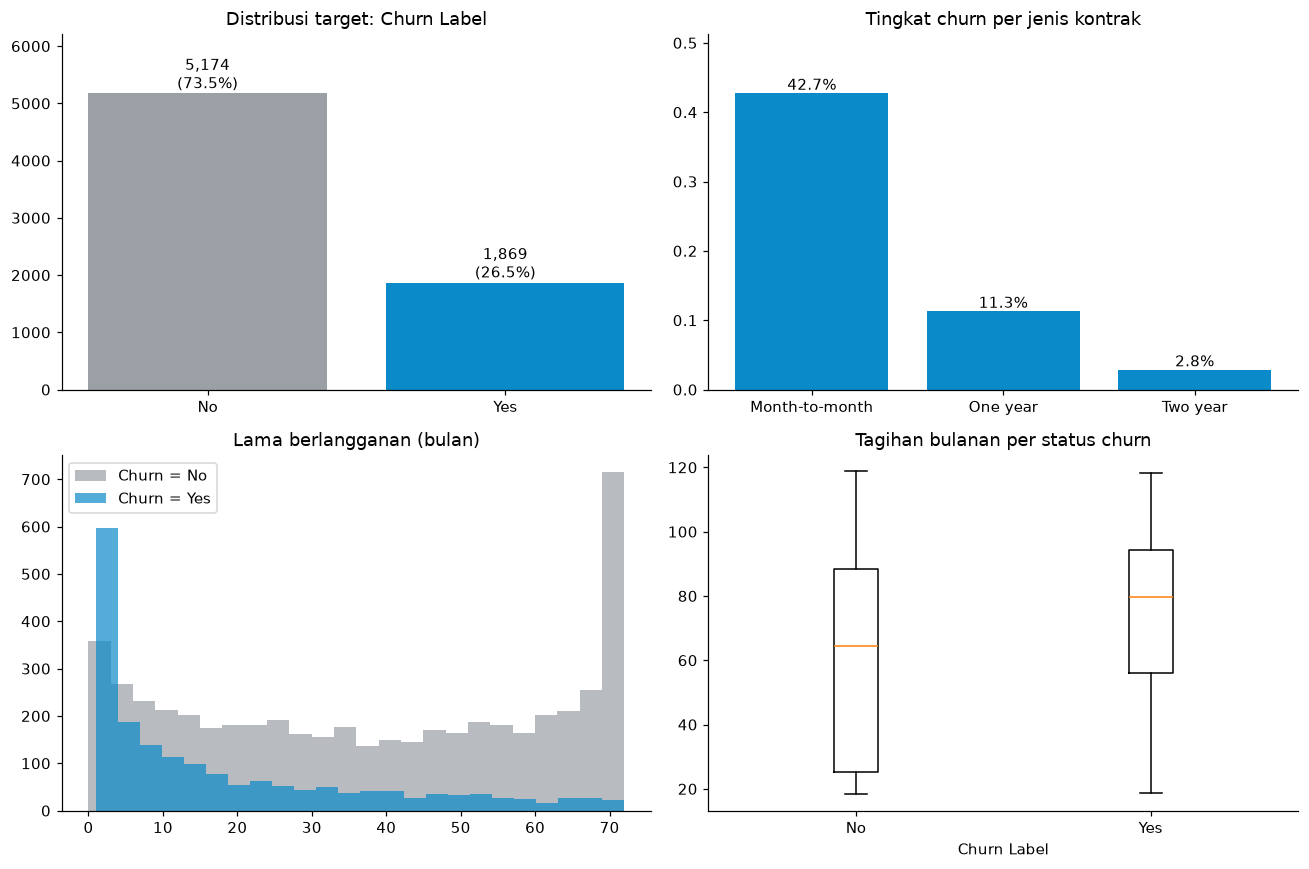

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
counts = telco_raw[TELCO_TARGET].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=[GREY, BLUE])
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v, f"{v:,}\n({v / len(telco_raw):.1%})", ha="center", va="bottom")
axes[0, 0].set_title("Distribusi target: Churn Label")
axes[0, 0].set_ylim(0, counts.max() * 1.2)

by_contract = telco_raw.groupby("Contract")[TELCO_TARGET].apply(lambda s: (s == "Yes").mean()).sort_values(ascending=False)
axes[0, 1].bar(by_contract.index, by_contract.values, color=BLUE)
for i, v in enumerate(by_contract.values):
    axes[0, 1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
axes[0, 1].set_title("Tingkat churn per jenis kontrak")
axes[0, 1].set_ylim(0, by_contract.max() * 1.2)

for label, color in [("No", GREY), ("Yes", BLUE)]:
    axes[1, 0].hist(telco_raw.loc[telco_raw[TELCO_TARGET] == label, "Tenure Months"], bins=24, alpha=0.7, label=f"Churn = {label}", color=color)
axes[1, 0].set_title("Lama berlangganan (bulan)")
axes[1, 0].legend()

axes[1, 1].boxplot([telco_raw.loc[telco_raw[TELCO_TARGET] == lbl, "Monthly Charges"] for lbl in ["No", "Yes"]], tick_labels=["No", "Yes"])
axes[1, 1].set_title("Tagihan bulanan per status churn")
axes[1, 1].set_xlabel("Churn Label")
plt.tight_layout()
plt.show()

**Yang terlihat dari EDA:**

- **Data tidak seimbang.** Hanya 26,5% pelanggan yang churn. Akurasi harus selalu dibandingkan dengan baseline, dan metrik seperti F1 dan ROC-AUC perlu ikut dilaporkan.
- **Jenis kontrak sangat menentukan.** Tingkat churn pelanggan bulanan (*month-to-month*) 42,7%, jauh di atas kontrak satu tahun (11,3%) dan dua tahun (2,8%).
- **Pelanggan baru lebih mudah pergi.** Median lama berlangganan pelanggan yang churn hanya 10 bulan, dibanding 38 bulan untuk yang bertahan.
- **Tagihan tinggi berkaitan dengan churn.** Median tagihan bulanan pelanggan churn 79,65, dibanding 64,43 untuk yang bertahan.

## A.4 Pembersihan data

Langkah pembersihan memakai fungsi yang sama dengan aplikasi web:

1. **Buang kolom bocor secara manual** (`Churn Score`, `Churn Reason`, `CLTV`), karena tidak bisa dideteksi otomatis.
2. **`clean_string_cells`:** spasi kosong `" "` di semua kolom teks diubah menjadi nilai kosong.
3. **`encode_target`:** `Yes` menjadi 1, `No` menjadi 0.
4. **`drop_useless_features`:** buang kolom ID, konstan, teks dengan lebih dari 50 kategori, dan fitur yang hampir identik dengan target (termasuk `Churn Value`).
5. **`cast_numeric_strings`:** kolom teks yang isinya angka (seperti `Total Charges`) diubah menjadi numerik.
6. **`impute_missing`:** nilai kosong numerik diisi median, kategorikal diisi modus.
7. **One-hot encoding** dan pembagian **80% latih / 20% uji secara stratified** (proporsi churn sama di kedua bagian).

In [10]:
telco = prepare(telco_raw, TELCO_TARGET, TELCO_LEAKAGE)
print("Kelas positif (1):", telco.mapping["positive_class"], "| kelas negatif (0):", telco.mapping["negative_class"])
print("Dibuang manual:", telco.excluded)
print("Nilai kosong sebelum imputasi:", telco.missing_before, "| sesudah:", int(telco.X.isna().sum().sum()))
print(f"Setelah dibersihkan: {telco.X.shape[0]:,} baris x {telco.X.shape[1]} fitur | setelah encoding: {telco.X_enc.shape[1]} fitur")
print(f"Data latih: {len(telco.X_train):,} (churn {telco.y_train.mean():.1%}) | data uji: {len(telco.X_test):,} (churn {telco.y_test.mean():.1%}) | scale_pos_weight = {telco.spw:.3f}")
pd.Series(telco.dropped, name="alasan dibuang otomatis").to_frame()

Kelas positif (1): Yes | kelas negatif (0): No
Dibuang manual: ['Churn Score', 'Churn Reason', 'CLTV']
Nilai kosong sebelum imputasi: {'Total Charges': 11} | sesudah: 0
Setelah dibersihkan: 7,043 baris x 22 fitur | setelah encoding: 33 fitur
Data latih: 5,634 (churn 26.5%) | data uji: 1,409 (churn 26.5%) | scale_pos_weight = 2.769


,alasan dibuang otomatis
CustomerID,ID-like (every value is unique)
Count,constant column
Country,constant column
State,constant column
City,high-cardinality text (1129 categories > 50)
Lat Long,high-cardinality text (1652 categories > 50)
Churn Value,target leakage (|corr with target| = 1.000)


Catatan: 11 nilai `Total Charges` yang kosong milik pelanggan dengan `Tenure Months` = 0. Secara bisnis, nilai yang paling tepat adalah 0 (belum ada tagihan). Pipeline universal mengisinya dengan median karena tidak tahu arti kolom tersebut. Dampaknya kecil (11 dari 7.043 baris, 0,16%), tetapi tetap dicatat di sini.

In [11]:
CLEAN_DIR = ROOT / "data" / "clean"
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
telco_clean_path = CLEAN_DIR / "telco_churn_clean.csv"
telco.X.assign(**{TELCO_TARGET: telco.df[TELCO_TARGET].values}).to_csv(telco_clean_path, index=False)
print(f"Dataset bersih disimpan: {telco_clean_path.relative_to(ROOT)}")

Dataset bersih disimpan: data/clean/telco_churn_clean.csv


## A.5 Baseline

"Model" yang selalu menebak kelas terbanyak (tidak churn). Karena hanya 26,5% pelanggan yang churn, **baseline ini sudah mendapat akurasi sekitar 73%**, padahal tidak pernah menemukan satu pun pelanggan yang churn.

In [12]:
telco_base = baseline(telco)
pd.Series(telco_base).to_frame("nilai")

,nilai
model,Baseline (kelas terbanyak)
accuracy,0.734564
precision,0.0
recall,0.0
f1,0.0
roc_auc,0.5


## A.6 Melatih dan membandingkan 6 model (mode bisnis)

Setiap model mendapat perlakuan yang sama:

- **Hyperparameter bersama:** `max_depth=5`, `learning_rate=0.05`, `n_estimators=150`, dipakai oleh model yang punya padanannya.
- **Penanganan ketidakseimbangan kelas:** XGBoost, LightGBM, dan CatBoost memakai `scale_pos_weight`; model scikit-learn memakai `class_weight="balanced"`.
- **Threshold yang memaksimalkan F1** dicari dari **prediksi validasi silang 5-fold di data latih**, bukan dari data uji, sehingga skor di data uji tetap jujur.

In [13]:
telco_bis = train_all(telco, "bisnis")
cv_table(telco_bis)

Model,Threshold,F1 (CV),F1 std,Akurasi (CV),ROC-AUC (CV),ROC-AUC std
CatBoost,0.580,0.660,0.026,0.796,0.866,0.013
XGBoost,0.490,0.650,0.020,0.770,0.863,0.011
LightGBM,0.540,0.650,0.023,0.780,0.861,0.011
Logistic Regression,0.600,0.649,0.024,0.790,0.858,0.012
HistGradientBoosting,0.570,0.649,0.019,0.787,0.861,0.010
Random Forest,0.550,0.648,0.023,0.782,0.857,0.011


In [14]:
test_table(telco_bis, telco_base)

Model,Akurasi,Akurasi @0.5,Precision,Recall,F1,ROC-AUC,PR-AUC,Waktu latih (s)
CatBoost,0.777,0.756,0.560,0.746,0.640,0.860,0.675,0.192
XGBoost,0.750,0.755,0.519,0.805,0.631,0.851,0.662,0.093
LightGBM,0.762,0.754,0.536,0.762,0.629,0.850,0.659,0.085
Logistic Regression,0.776,0.742,0.561,0.717,0.629,0.848,0.640,0.018
HistGradientBoosting,0.768,0.752,0.546,0.741,0.629,0.850,0.657,0.230
Random Forest,0.767,0.750,0.545,0.722,0.621,0.848,0.652,0.199
Baseline (kelas terbanyak),0.735,-,0.000,0.000,0.000,0.500,-,-


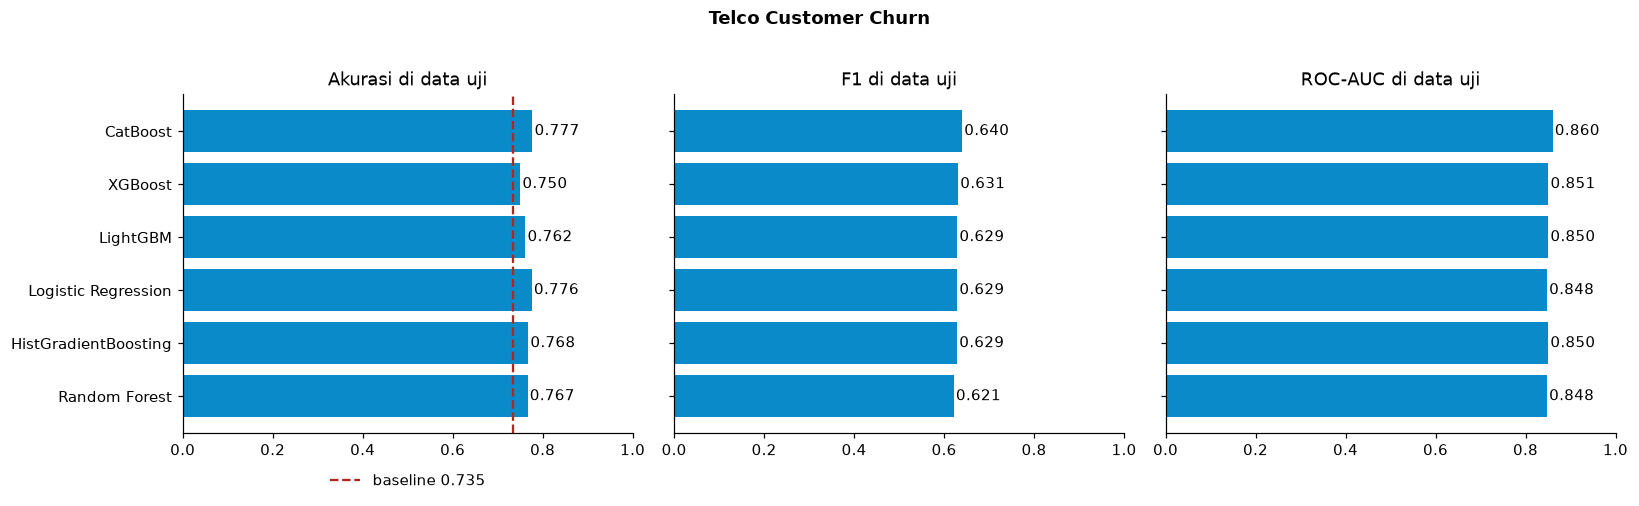

In [15]:
plot_scores(telco_bis, telco_base, "Telco Customer Churn")

**Membaca hasil perbandingan:**

- **CatBoost terbaik di kedua ukuran:** F1 tertinggi di validasi silang (0,660) dan di data uji (F1 0,640, akurasi 0,777, ROC-AUC 0,860).
- **Selisih antarmodel kecil.** F1 validasi silang keenam model berada di rentang 0,648 sampai 0,660, sementara simpangan baku antar-fold sekitar 0,02. Perbedaan antarmodel lebih kecil dari variasi akibat pembagian data, jadi urutan peringkat tidak boleh dibaca terlalu kaku.
- **Logistic Regression hampir menyamai model boosting** (F1 0,629, akurasi 0,776), padahal jauh lebih sederhana.
- **Akurasi versus baseline.** Akurasi model terbaik 0,777, atau 4,2 poin di atas baseline 0,735. Kenaikan itu terlihat kecil, tetapi baseline tidak menemukan satu pun pelanggan churn (recall 0), sedangkan CatBoost menemukan 74,6% di antaranya.

## A.7 Analisis model terbaik

Model terbaik dipilih berdasarkan **F1 rata-rata di validasi silang**, bukan skor data uji, supaya data uji tidak ikut memengaruhi pemilihan.

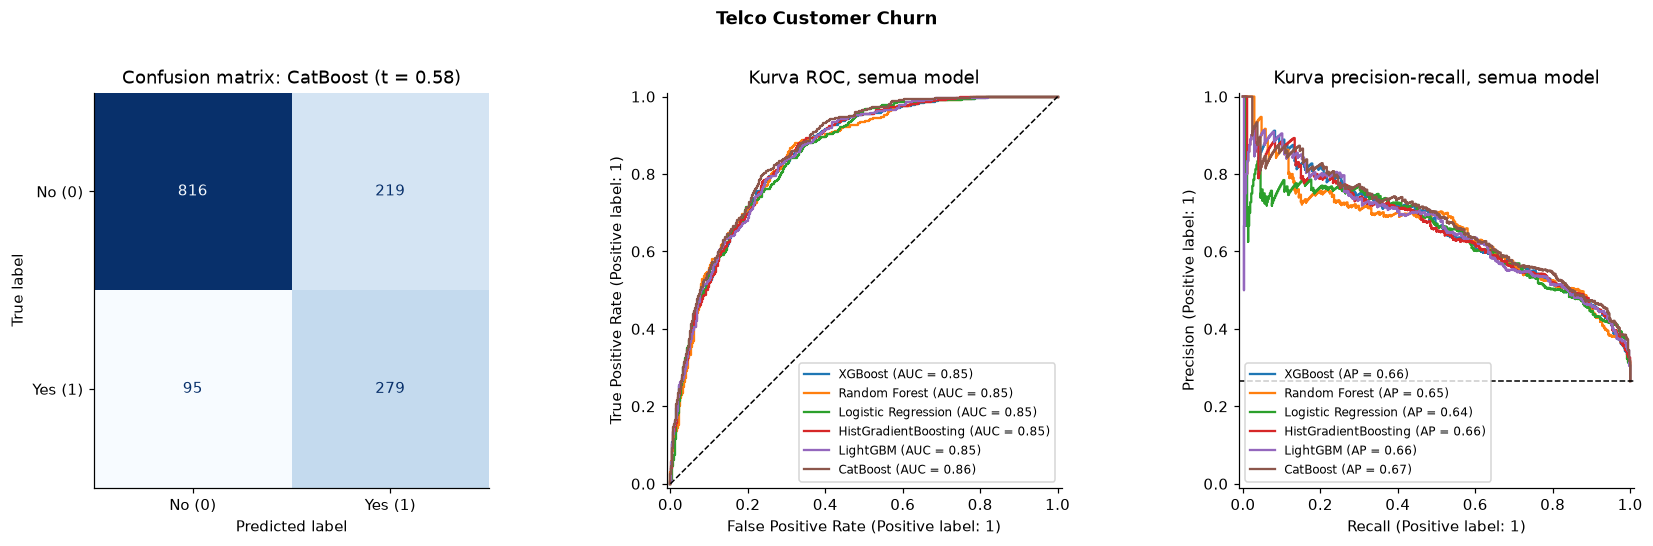

In [16]:
plot_best(telco, telco_bis, "Telco Customer Churn")

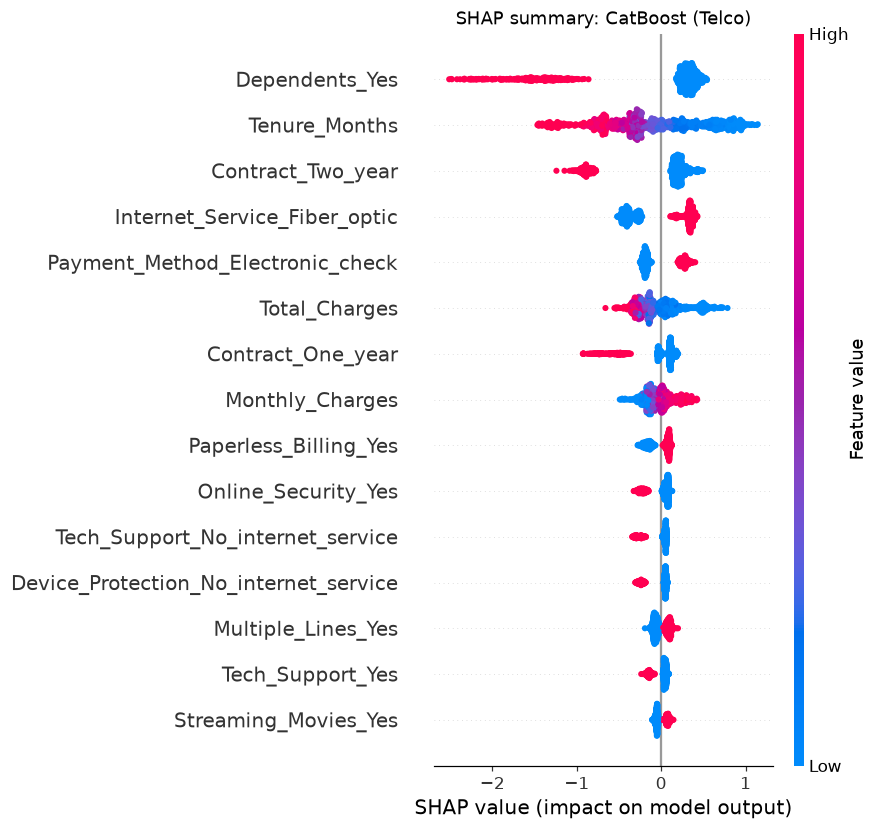

,rata-rata |SHAP|
Dependents_Yes,0.622886
Tenure_Months,0.518472
Contract_Two_year,0.371813
Internet_Service_Fiber_optic,0.357848
Payment_Method_Electronic_check,0.217878
Total_Charges,0.214037
Contract_One_year,0.196366
Monthly_Charges,0.129702
Paperless_Billing_Yes,0.112937
Online_Security_Yes,0.105133


In [17]:
telco_importance = shap_importance(telco, telco_bis, "Telco")
telco_importance.head(10).rename("rata-rata |SHAP|").to_frame()

**Fitur yang paling berpengaruh** menurut SHAP sejalan dengan pola di data mentah:

- **`Dependents`:** pelanggan yang punya tanggungan jauh lebih jarang churn (6,5% dibanding 32,6%).
- **`Tenure Months`:** semakin lama berlangganan, semakin kecil peluang churn.
- **`Contract`:** kontrak dua tahun dan satu tahun menurunkan peluang churn.
- **`Internet Service` = Fiber optic:** pelanggan fiber optic churn 41,9%, dibanding 19,0% untuk DSL.
- **`Payment Method` = Electronic check** dan **`Total Charges`** melengkapi lima besar.

Tidak ada satu fitur pun yang mendominasi secara mencurigakan. Ini tanda bahwa kolom bocor sudah berhasil dibuang.

## A.8 Mode akurasi vs mode bisnis

Model yang sama bisa dipakai dengan dua tujuan berbeda:

| | Mode bisnis (A.6) | Mode akurasi |
|---|---|---|
| Bobot kelas | `scale_pos_weight` / `class_weight="balanced"` | tidak ada, kedua kelas dianggap sama penting |
| Threshold dipilih untuk | F1 tertinggi | akurasi tertinggi |
| Cocok jika | kehilangan pelanggan jauh lebih mahal daripada menghubungi pelanggan yang tidak akan pergi | setiap tebakan salah sama mahalnya |

Di kedua mode, threshold dipilih dari validasi silang di data latih.

In [18]:
telco_acc = train_all(telco, "akurasi")
telco_modes = modes_table(telco_bis, telco_acc)
fmt3(telco_modes)

Model,Threshold (akurasi),Akurasi (akurasi),Recall (akurasi),F1 (akurasi),Threshold (bisnis),Akurasi (bisnis),Recall (bisnis),F1 (bisnis)
Logistic Regression,0.530,0.803,0.537,0.592,0.600,0.776,0.717,0.629
CatBoost,0.490,0.811,0.564,0.612,0.580,0.777,0.746,0.640
XGBoost,0.500,0.801,0.537,0.589,0.490,0.750,0.805,0.631
LightGBM,0.530,0.806,0.500,0.578,0.540,0.762,0.762,0.629
Random Forest,0.430,0.805,0.572,0.609,0.550,0.767,0.722,0.621
HistGradientBoosting,0.510,0.806,0.529,0.591,0.570,0.768,0.741,0.629


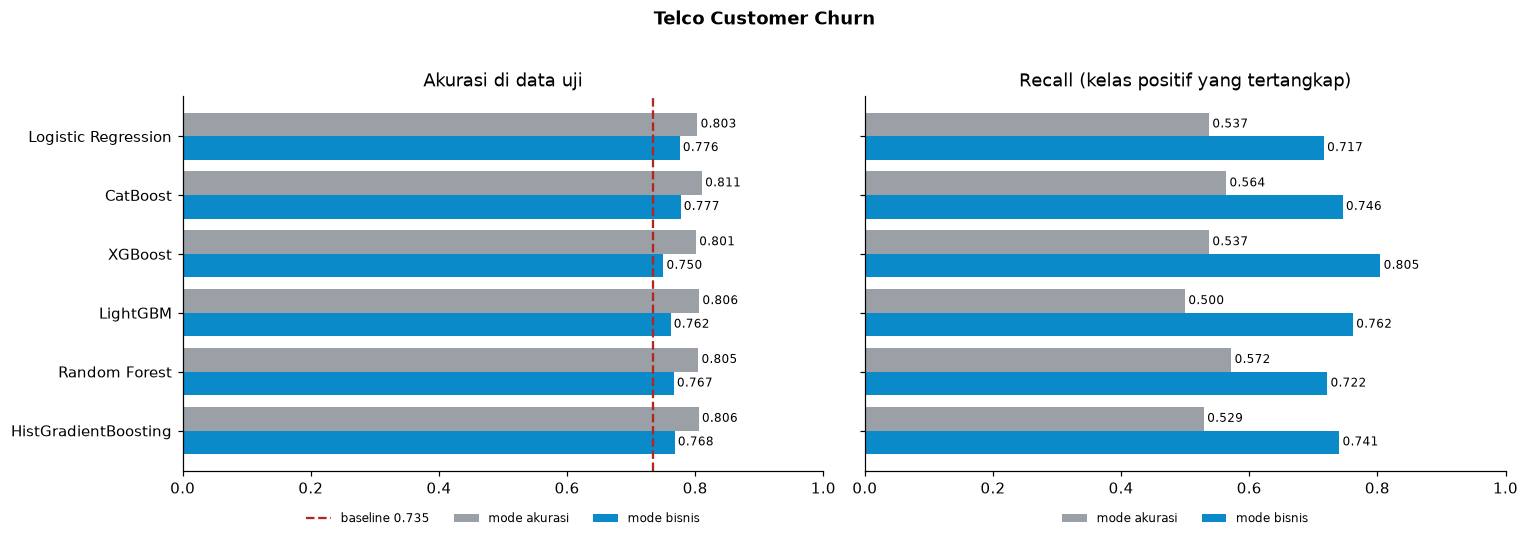

In [19]:
plot_modes(telco_modes, telco_acc, telco_base, "Telco Customer Churn")

In [20]:
counts_table(telco, telco_bis, telco_acc)

mode,model,threshold,positif tertangkap,positif terlewat,alarm palsu,total salah,akurasi
Mode akurasi,Logistic Regression,0.53,201,173,104,277,0.803
Mode bisnis,CatBoost,0.58,279,95,219,314,0.777


**Membaca hasil kedua mode:**

- **Mode akurasi menaikkan akurasi semua model ke rentang 0,801 sampai 0,811**, dibanding 0,750 sampai 0,777 di mode bisnis. Model terbaik menurut validasi silang adalah Logistic Regression (0,803 di data uji). CatBoost sedikit lebih tinggi di data uji (0,811), tetapi memilih model berdasarkan data uji akan membuat skornya bias.
- **Harga dari akurasi yang lebih tinggi adalah recall.** Mode akurasi membuat 37 kesalahan lebih sedikit secara total (277 dibanding 314), tetapi **melewatkan 78 pelanggan churn lebih banyak** (173 dibanding 95).
- **Batas atas yang jujur sekitar 0,81.** Keenam model, dengan dua cara pengaturan, berhenti di sekitar angka itu. Akurasi di atas 85% untuk dataset ini hanya tercapai dengan kolom bocor (A.2).

## A.9 Menyimpan model dan uji muat ulang

Keenam model (mode bisnis) disimpan ke `models/telco/`, model terbaik mode akurasi ke `models/telco/accuracy_mode/`, beserta `metadata.json` (urutan fitur, threshold, skor). Model scikit-learn disimpan dengan `joblib` (berbasis *pickle*): hanya buka file `.joblib` dari sumber yang dipercaya.

In [21]:
files = save_models("telco", "IBM Telco Customer Churn (data/raw/Telco_customer_churn.csv)", telco, telco_bis, telco_acc,
                    telco_clean_path, TELCO_LEAKAGE)
reload_check("telco", telco, telco_bis)
files

Model dimuat ulang dari models/telco/: CatBoost | prediksi identik dengan model di memori: True


,file,ukuran (KB)
0,models/telco/accuracy_mode/logistic_regression...,3.3
1,models/telco/catboost_model.cbm,95.6
2,models/telco/hist_gradient_boosting_model.joblib,425.3
3,models/telco/lightgbm_model.txt,386.5
4,models/telco/logistic_regression_model.joblib,3.4
5,models/telco/metadata.json,3.7
6,models/telco/random_forest_model.joblib,732.0
7,models/telco/xgboost_model.json,445.2


## A.10 Ringkasan Bagian A

- Dataset Telco **kotor ringan**: 11 spasi kosong, 3 kolom konstan, 1 ID, 2 kolom teks dengan ribuan kategori, dan 4 kolom bocor.
- **Mode bisnis:** CatBoost terbaik dengan akurasi 0,777, F1 0,640, ROC-AUC 0,860, dan menemukan 279 dari 374 pelanggan churn di data uji.
- **Mode akurasi:** Logistic Regression terbaik menurut validasi silang dengan akurasi 0,803; semua model berada di 0,801 sampai 0,811.
- **Faktor churn utama:** tidak punya tanggungan, masa berlangganan pendek, kontrak bulanan, fiber optic, dan electronic check.

---

# Bagian B: Bank Marketing

**Pertanyaan:** apakah seorang nasabah akan membuka deposito berjangka setelah dihubungi lewat telepon dalam kampanye pemasaran bank?

**Dataset:** Bank Marketing (versi `bank.csv` dari Kaggle, berasal dari kampanye telepon sebuah bank di Portugal), 11.162 nasabah. Target: `deposit` (yes/no).

## B.1 Memuat data mentah

In [22]:
BANK_TARGET = "deposit"
bank_raw = read_dataset(ROOT / "data" / "raw" / "bank.csv")
print(f"Ukuran: {bank_raw.shape[0]:,} baris x {bank_raw.shape[1]} kolom | pemisah {bank_raw.attrs['separator']!r} | encoding {bank_raw.attrs['encoding']}")
bank_raw.head()

Ukuran: 11,162 baris x 17 kolom | pemisah ',' | encoding utf-8-sig


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


## B.2 Audit kualitas data: apakah dataset ini kotor?

In [23]:
audit(bank_raw)

,kolom,masalah,jumlah
0,job,"nilai kosong yang menyamar ('unknown', '?', ...)",70
1,education,"nilai kosong yang menyamar ('unknown', '?', ...)",497
2,contact,"nilai kosong yang menyamar ('unknown', '?', ...)",2346
3,poutcome,"nilai kosong yang menyamar ('unknown', '?', ...)",8326


**Dataset Bank termasuk kotor ringan, dengan jenis kotoran yang berbeda dari Telco.** Tidak ada sel kosong, spasi kosong, kolom konstan, maupun ID. Masalahnya adalah **nilai kosong yang menyamar**: kata `unknown` dipakai sebagai pengganti data yang tidak tersedia di empat kolom, yaitu `job` (70 baris), `education` (497), `contact` (2.346), dan `poutcome` (8.326). Karena berupa teks biasa, pemeriksaan nilai kosong standar (`isna()`) tidak akan menemukannya.

In [24]:
pdays_never = (bank_raw["pdays"] == -1)
pd.DataFrame({
    "pemeriksaan": ["pdays = -1 (belum pernah dihubungi sebelumnya)", "poutcome = 'unknown'", "keduanya terjadi bersamaan",
                    "previous = 0 (tidak ada kontak sebelumnya)"],
    "jumlah baris": [int(pdays_never.sum()), int((bank_raw["poutcome"] == "unknown").sum()),
                     int((pdays_never & (bank_raw["poutcome"] == "unknown")).sum()), int((bank_raw["previous"] == 0).sum())],
}).assign(persentase=lambda t: (t["jumlah baris"] / len(bank_raw)).map("{:.1%}".format))

,pemeriksaan,jumlah baris,persentase
0,pdays = -1 (belum pernah dihubungi sebelumnya),8324,74.6%
1,poutcome = 'unknown',8326,74.6%
2,keduanya terjadi bersamaan,8324,74.6%
3,previous = 0 (tidak ada kontak sebelumnya),8324,74.6%


Ada juga **nilai pengganti (*sentinel*) di kolom angka**: `pdays = -1` berarti nasabah belum pernah dihubungi pada kampanye sebelumnya. Kondisi ini terjadi di 8.324 baris (74,6%), dan selalu bersamaan dengan `poutcome = unknown` dan `previous = 0`. Jadi tiga kolom menyimpan informasi yang sama, yaitu "nasabah baru dalam kampanye ini". Nilai -1 bukan jumlah hari yang sebenarnya: model linear akan membacanya sebagai angka kecil biasa, sedangkan model berbasis pohon bisa memisahkannya.

### Kebocoran data: kolom `duration`

`duration` adalah lama telepon dalam detik. Angka ini **baru diketahui setelah telepon selesai**, saat nasabah sudah memberi jawaban. Pembuat dataset aslinya sendiri menyarankan kolom ini dibuang untuk model prediksi yang realistis. Korelasinya dengan target hanya sedang, sehingga penjaga kebocoran otomatis tidak menangkapnya; jenis kebocoran seperti ini hanya bisa dikenali dari pemahaman domain.

In [25]:
BANK_LEAKAGE = ["duration"]
print(f"Korelasi duration dengan target: {bank_raw['duration'].corr((bank_raw[BANK_TARGET] == 'yes').astype(int)):.3f}")
leakage_impact(bank_raw, BANK_TARGET, BANK_LEAKAGE).style.format("{:.3f}")

Korelasi duration dengan target: 0.452


,akurasi,ROC-AUC
dengan kolom bocor,0.856,0.928
tanpa kolom bocor,0.738,0.793


Dengan `duration`, akurasi CatBoost **0,856** (ROC-AUC 0,928). Tanpa `duration`, akurasinya **0,738** (ROC-AUC 0,793). Selisih hampir 12 poin itu adalah akurasi palsu: bank tidak mungkin tahu lama telepon sebelum menelepon. Boxplot di B.3 menunjukkan alasannya: median lama telepon nasabah yang membuka deposito 426 detik, dibanding 163 detik untuk yang menolak. `duration` dibuang di langkah pembersihan.

## B.3 Eksplorasi data (EDA)

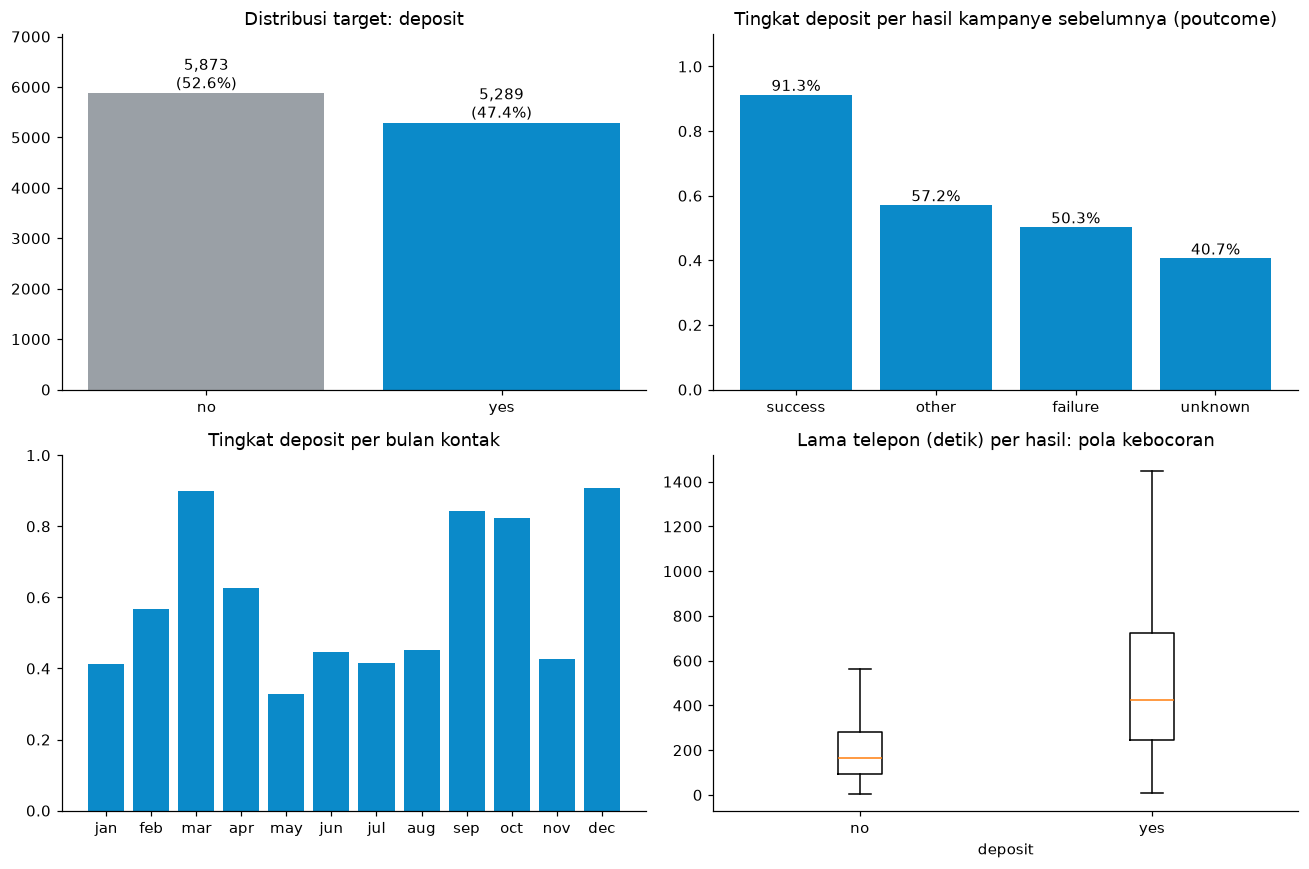

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
counts = bank_raw[BANK_TARGET].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=[GREY, BLUE])
for i, v in enumerate(counts.values):
    axes[0, 0].text(i, v, f"{v:,}\n({v / len(bank_raw):.1%})", ha="center", va="bottom")
axes[0, 0].set_title("Distribusi target: deposit")
axes[0, 0].set_ylim(0, counts.max() * 1.2)

rate = lambda col: bank_raw.groupby(col)[BANK_TARGET].apply(lambda s: (s == "yes").mean())
by_pout = rate("poutcome").sort_values(ascending=False)
axes[0, 1].bar(by_pout.index, by_pout.values, color=BLUE)
for i, v in enumerate(by_pout.values):
    axes[0, 1].text(i, v, f"{v:.1%}", ha="center", va="bottom")
axes[0, 1].set_title("Tingkat deposit per hasil kampanye sebelumnya (poutcome)")
axes[0, 1].set_ylim(0, 1.1)

months = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
by_month = rate("month").reindex(months)
axes[1, 0].bar(by_month.index, by_month.values, color=BLUE)
axes[1, 0].set_title("Tingkat deposit per bulan kontak")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].boxplot([bank_raw.loc[bank_raw[BANK_TARGET] == lbl, "duration"] for lbl in ["no", "yes"]], tick_labels=["no", "yes"], showfliers=False)
axes[1, 1].set_title("Lama telepon (detik) per hasil: pola kebocoran")
axes[1, 1].set_xlabel("deposit")
plt.tight_layout()
plt.show()

In [27]:
pd.DataFrame({
    "tingkat deposit keseluruhan": [f"{(bank_raw[BANK_TARGET] == 'yes').mean():.1%}"],
    "kontak via cellular": [f"{rate('contact').get('cellular', np.nan):.1%}"],
    "kontak 'unknown'": [f"{rate('contact').get('unknown', np.nan):.1%}"],
    "median lama telepon (yes)": [bank_raw.loc[bank_raw[BANK_TARGET] == "yes", "duration"].median()],
    "median lama telepon (no)": [bank_raw.loc[bank_raw[BANK_TARGET] == "no", "duration"].median()],
    "bulan dengan kontak terbanyak": [bank_raw["month"].value_counts().idxmax()],
}).T.rename(columns={0: "nilai"})

,nilai
tingkat deposit keseluruhan,47.4%
kontak via cellular,54.3%
kontak 'unknown',22.6%
median lama telepon (yes),426.0
median lama telepon (no),163.0
bulan dengan kontak terbanyak,may


**Yang terlihat dari EDA:**

- **Kelas hampir seimbang** (47,4% yes). Berbeda dengan Telco, akurasi di sini lebih bermakna karena baseline-nya rendah.
- **Riwayat kampanye sangat menentukan.** Nasabah yang kampanye sebelumnya berhasil (`poutcome = success`) membuka deposito 91,3%, dibanding 40,7% untuk nasabah yang belum pernah dihubungi (`unknown`).
- **Cara menghubungi berpengaruh.** Tingkat deposit lewat ponsel (*cellular*) 54,3%, sedangkan untuk kontak yang tidak tercatat (`unknown`) hanya 22,6%.
- **Bulan kontak berpengaruh kuat.** Mei adalah bulan dengan kontak terbanyak (25,3% dari semua kontak) tetapi tingkat deposit terendah (32,8%), sedangkan Maret, September, Oktober, dan Desember berada di atas 80%.
- **Pola kebocoran terlihat jelas** di boxplot lama telepon (lihat B.2).

## B.4 Pembersihan data

Fungsi yang sama dengan Bagian A. Perbedaannya hanya kolom bocor yang dibuang manual (`duration`). Nilai `unknown` **sengaja dipertahankan sebagai kategori tersendiri**, karena "tidak diketahui" di sini membawa informasi (misalnya `contact = unknown` berasosiasi dengan tingkat deposit yang jauh lebih rendah). Nilai `pdays = -1` juga dipertahankan; model berbasis pohon bisa memisahkannya dari nilai lain dengan sendirinya.

In [28]:
bank = prepare(bank_raw, BANK_TARGET, BANK_LEAKAGE)
print("Kelas positif (1):", bank.mapping["positive_class"], "| kelas negatif (0):", bank.mapping["negative_class"])
print("Dibuang manual:", bank.excluded, "| dibuang otomatis:", bank.dropped or "tidak ada")
print("Nilai kosong sebelum imputasi:", bank.missing_before or "tidak ada")
print(f"Setelah dibersihkan: {bank.X.shape[0]:,} baris x {bank.X.shape[1]} fitur | setelah encoding: {bank.X_enc.shape[1]} fitur")
print(f"Data latih: {len(bank.X_train):,} (yes {bank.y_train.mean():.1%}) | data uji: {len(bank.X_test):,} (yes {bank.y_test.mean():.1%}) | scale_pos_weight = {bank.spw:.3f}")

bank_clean_path = CLEAN_DIR / "bank_marketing_clean.csv"
bank.X.assign(**{BANK_TARGET: bank.df[BANK_TARGET].values}).to_csv(bank_clean_path, index=False)
print(f"Dataset bersih disimpan: {bank_clean_path.relative_to(ROOT)}")

Kelas positif (1): yes | kelas negatif (0): no
Dibuang manual: ['duration'] | dibuang otomatis: tidak ada
Nilai kosong sebelum imputasi: tidak ada
Setelah dibersihkan: 11,162 baris x 15 fitur | setelah encoding: 41 fitur
Data latih: 8,929 (yes 47.4%) | data uji: 2,233 (yes 47.4%) | scale_pos_weight = 1.110
Dataset bersih disimpan: data/clean/bank_marketing_clean.csv


## B.5 Baseline

In [29]:
bank_base = baseline(bank)
pd.Series(bank_base).to_frame("nilai")

,nilai
model,Baseline (kelas terbanyak)
accuracy,0.526198
precision,0.0
recall,0.0
f1,0.0
roc_auc,0.5


Baseline Bank hanya **0,526**, jauh di bawah baseline Telco (0,735). Setiap model harus melewati angka ini untuk dianggap belajar sesuatu.

## B.6 Melatih dan membandingkan 6 model (mode bisnis)

Pengaturan sama persis dengan A.6. Karena kelasnya hampir seimbang, `scale_pos_weight` di sini hanya sekitar 1,1, sehingga bobot kelas hampir tidak mengubah apa pun.

In [30]:
bank_bis = train_all(bank, "bisnis")
cv_table(bank_bis)

Model,Threshold,F1 (CV),F1 std,Akurasi (CV),ROC-AUC (CV),ROC-AUC std
LightGBM,0.380,0.709,0.005,0.689,0.790,0.005
XGBoost,0.370,0.708,0.003,0.683,0.790,0.004
HistGradientBoosting,0.390,0.708,0.005,0.693,0.789,0.005
CatBoost,0.450,0.706,0.005,0.719,0.788,0.004
Logistic Regression,0.390,0.691,0.007,0.654,0.763,0.008
Random Forest,0.440,0.687,0.010,0.657,0.761,0.010


In [31]:
test_table(bank_bis, bank_base)

Model,Akurasi,Akurasi @0.5,Precision,Recall,F1,ROC-AUC,PR-AUC,Waktu latih (s)
LightGBM,0.687,0.740,0.636,0.792,0.705,0.795,0.794,0.082
XGBoost,0.684,0.738,0.629,0.811,0.709,0.796,0.798,0.091
HistGradientBoosting,0.706,0.742,0.660,0.782,0.716,0.794,0.792,0.233
CatBoost,0.728,0.738,0.712,0.716,0.714,0.792,0.790,0.233
Logistic Regression,0.652,0.693,0.600,0.802,0.686,0.758,0.759,0.014
Random Forest,0.664,0.710,0.611,0.802,0.693,0.764,0.764,0.242
Baseline (kelas terbanyak),0.526,-,0.000,0.000,0.000,0.500,-,-


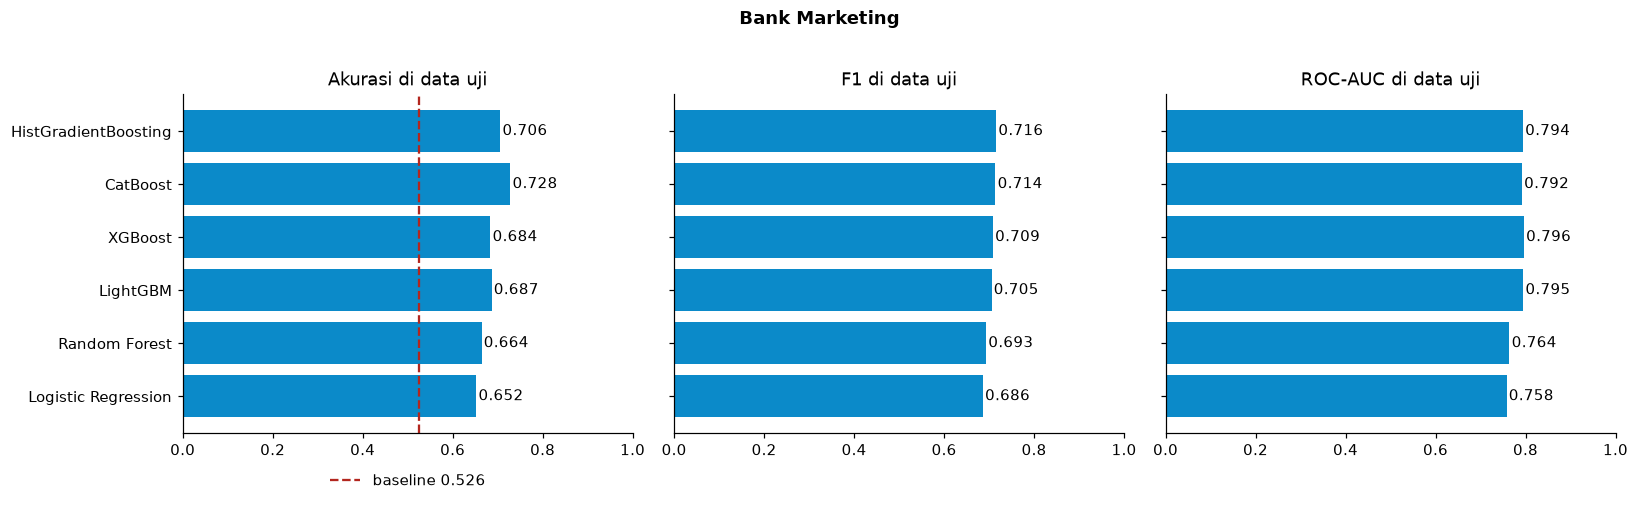

In [32]:
plot_scores(bank_bis, bank_base, "Bank Marketing")

**Membaca hasil perbandingan:**

- **Empat model boosting hampir sama kuat.** F1 validasi silang LightGBM, XGBoost, HistGradientBoosting, dan CatBoost berada di 0,706 sampai 0,709, dengan simpangan baku sekitar 0,005. LightGBM terpilih sebagai yang terbaik, tetapi selisihnya tidak bermakna.
- **Logistic Regression dan Random Forest tertinggal** (F1 sekitar 0,69, ROC-AUC sekitar 0,76). Berbeda dengan Telco, di sini model boosting memberi keuntungan nyata.
- **Di data seimbang, mode bisnis justru menurunkan akurasi.** Threshold yang memaksimalkan F1 berada di 0,37 sampai 0,45, sehingga model lebih sering menebak "yes": recall naik (sekitar 0,8), tetapi akurasi LightGBM turun dari 0,740 (threshold 0,5) menjadi 0,687. Bagian B.8 membahas pilihan ini.
- **Semua model jauh di atas baseline:** ROC-AUC 0,79 sampai 0,80 untuk model boosting, dibanding 0,5.

## B.7 Analisis model terbaik

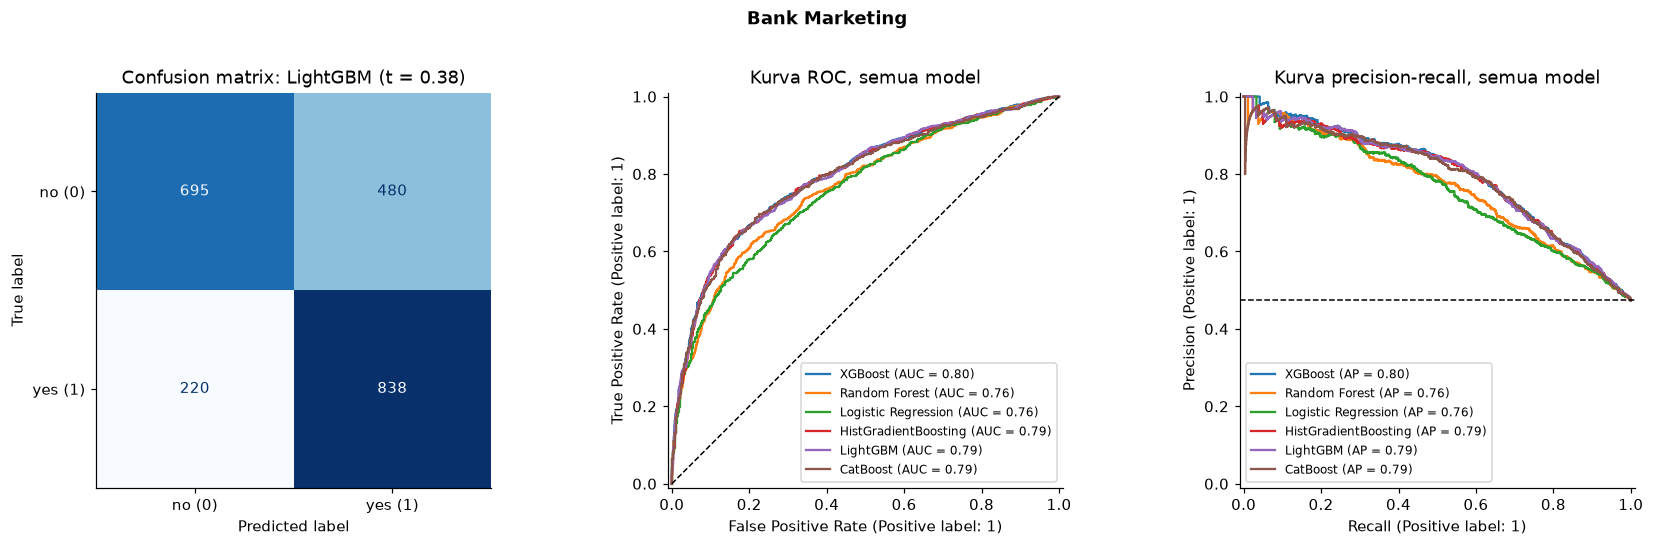

In [33]:
plot_best(bank, bank_bis, "Bank Marketing")

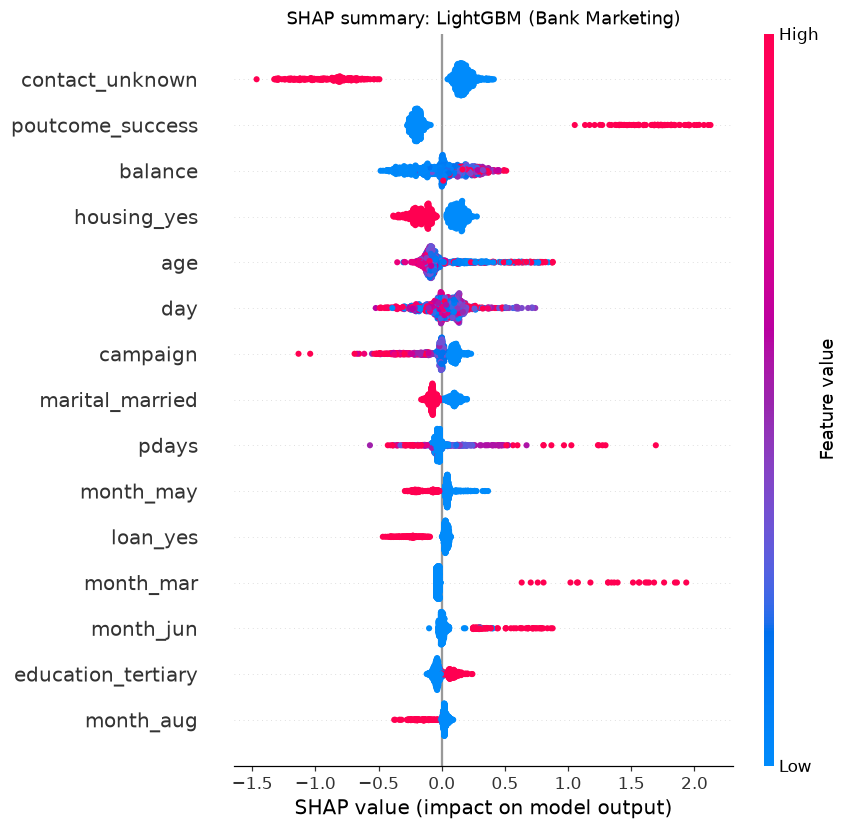

,rata-rata |SHAP|
contact_unknown,0.329929
poutcome_success,0.312866
balance,0.168861
housing_yes,0.147321
age,0.143501
day,0.119994
campaign,0.104084
marital_married,0.084787
pdays,0.077446
month_may,0.076316


In [34]:
bank_importance = shap_importance(bank, bank_bis, "Bank Marketing")
bank_importance.head(10).rename("rata-rata |SHAP|").to_frame()

**Fitur yang paling berpengaruh** (LightGBM) sejalan dengan EDA:

- **`contact = unknown`** menurunkan peluang deposit paling kuat (tingkat deposit 22,6%, dibanding 54,3% lewat ponsel).
- **`poutcome = success`** menaikkan peluang paling kuat (91,3%).
- **`balance`:** saldo yang lebih tinggi cenderung menaikkan peluang.
- **`housing = yes`** dan **`loan = yes`** menurunkan peluang: nasabah dengan cicilan rumah membuka deposito 36,6%, dibanding 57,0% tanpa cicilan.
- **`age`:** nasabah berusia di atas 60 tahun jauh lebih sering membuka deposito (82,2%).
- **`campaign`:** semakin sering dihubungi dalam kampanye yang sama, semakin kecil peluangnya.

Nilai `unknown` yang dipertahankan sebagai kategori ternyata menjadi fitur terpenting, sehingga keputusan untuk tidak membuangnya terbukti tepat.

## B.8 Mode akurasi vs mode bisnis

In [35]:
bank_acc = train_all(bank, "akurasi")
bank_modes = modes_table(bank_bis, bank_acc)
fmt3(bank_modes)

Model,Threshold (akurasi),Akurasi (akurasi),Recall (akurasi),F1 (akurasi),Threshold (bisnis),Akurasi (bisnis),Recall (bisnis),F1 (bisnis)
HistGradientBoosting,0.510,0.737,0.599,0.683,0.390,0.706,0.782,0.716
LightGBM,0.520,0.733,0.585,0.675,0.380,0.687,0.792,0.705
CatBoost,0.480,0.737,0.633,0.695,0.450,0.728,0.716,0.714
XGBoost,0.520,0.736,0.589,0.679,0.370,0.684,0.811,0.709
Random Forest,0.490,0.712,0.564,0.650,0.440,0.664,0.802,0.693
Logistic Regression,0.490,0.697,0.578,0.644,0.390,0.652,0.802,0.686


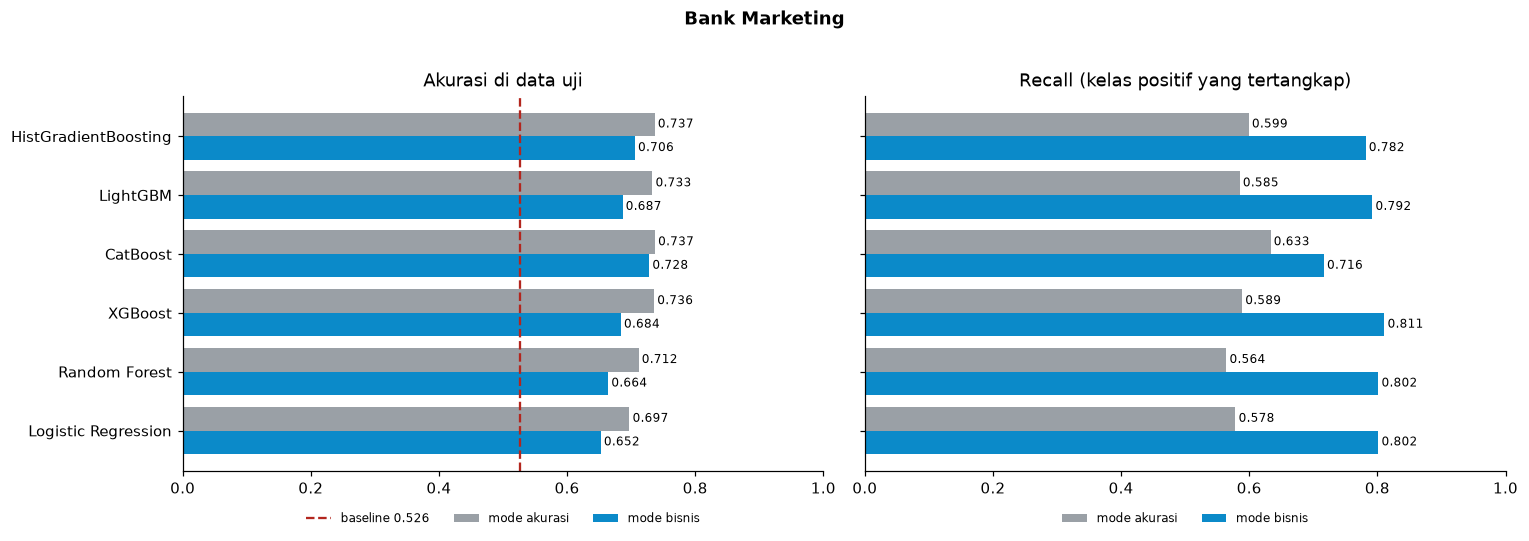

In [36]:
plot_modes(bank_modes, bank_acc, bank_base, "Bank Marketing")

In [37]:
counts_table(bank, bank_bis, bank_acc)

mode,model,threshold,positif tertangkap,positif terlewat,alarm palsu,total salah,akurasi
Mode akurasi,HistGradientBoosting,0.51,634,424,164,588,0.737
Mode bisnis,LightGBM,0.38,838,220,480,700,0.687


**Membaca hasil kedua mode:**

- **Mode akurasi:** HistGradientBoosting terbaik menurut validasi silang dengan akurasi **0,737** di data uji. Model boosting lain berada di 0,733 sampai 0,737; Random Forest 0,712 dan Logistic Regression 0,697.
- **Mode bisnis (LightGBM):** akurasi 0,687, tetapi menangkap **838** dari 1.058 nasabah yang membuka deposito, dibanding **634** di mode akurasi. Harganya 316 alarm palsu tambahan (480 dibanding 164).
- **Pilihan mode bergantung pada biaya.** Jika satu telepon murah dan satu nasabah deposito bernilai tinggi, mode bisnis lebih menguntungkan. Jika tim penjualan terbatas dan setiap telepon mahal, mode akurasi lebih tepat.

## B.9 Menyimpan model dan uji muat ulang

In [38]:
files = save_models("bank", "Bank Marketing, Kaggle bank.csv (data/raw/bank.csv)", bank, bank_bis, bank_acc,
                    bank_clean_path, BANK_LEAKAGE)
reload_check("bank", bank, bank_bis)
files

Model dimuat ulang dari models/bank/: LightGBM | prediksi identik dengan model di memori: True


,file,ukuran (KB)
0,models/bank/accuracy_mode/hist_gradient_boosti...,400.3
1,models/bank/catboost_model.cbm,95.6
2,models/bank/hist_gradient_boosting_model.joblib,399.6
3,models/bank/lightgbm_model.txt,374.4
4,models/bank/logistic_regression_model.joblib,3.4
5,models/bank/metadata.json,3.1
6,models/bank/random_forest_model.joblib,711.8
7,models/bank/xgboost_model.json,457.9


## B.10 Ringkasan Bagian B

- Dataset Bank **kotor ringan** dengan jenis kotoran yang berbeda dari Telco: nilai `unknown` yang menyamar di empat kolom, dan nilai pengganti `pdays = -1` di 74,6% baris.
- **`duration` membocorkan target.** Dengan kolom ini akurasi terlihat 0,856; tanpa kolom ini 0,738.
- **Mode bisnis:** LightGBM terbaik (F1 0,705, ROC-AUC 0,795, akurasi 0,687), menangkap 838 dari 1.058 nasabah yang membuka deposito.
- **Mode akurasi:** HistGradientBoosting terbaik dengan akurasi 0,737, atau 21 poin di atas baseline 0,526.
- **Faktor utama:** cara kontak, hasil kampanye sebelumnya, saldo, cicilan rumah, usia, dan bulan kontak.

---

# Bagian C: Perbandingan kedua dataset dan kesimpulan akhir

In [39]:
def summary_row(name, raw, target, d, base, bis, acc, leak_cols):
    leak = leakage_impact(raw, target, leak_cols)
    return {
        "Dataset": name, "Baris": len(d.df), "Fitur (encoded)": d.X_enc.shape[1],
        "Kelas positif": f"{d.y.mean():.1%}", "Akurasi baseline": base["accuracy"],
        "Model terbaik (bisnis)": bis.best["model"], "Akurasi (bisnis)": bis.best["accuracy"],
        "F1 (bisnis)": bis.best["f1"], "ROC-AUC (bisnis)": bis.best["roc_auc"],
        "Model terbaik (akurasi)": acc.best["model"], "Akurasi (akurasi)": acc.best["accuracy"],
        "Kolom bocor": ", ".join(leak_cols), "Akurasi jika bocor": leak.loc["dengan kolom bocor", "akurasi"],
    }

summary = pd.DataFrame([
    summary_row("Telco Customer Churn", telco_raw, TELCO_TARGET, telco, telco_base, telco_bis, telco_acc, TELCO_LEAKAGE),
    summary_row("Bank Marketing", bank_raw, BANK_TARGET, bank, bank_base, bank_bis, bank_acc, BANK_LEAKAGE),
]).set_index("Dataset").T
summary

Dataset,Telco Customer Churn,Bank Marketing
Baris,7043,11162
Fitur (encoded),33,41
Kelas positif,26.5%,47.4%
Akurasi baseline,0.734564,0.526198
Model terbaik (bisnis),CatBoost,LightGBM
Akurasi (bisnis),0.777147,0.68652
F1 (bisnis),0.639908,0.705387
ROC-AUC (bisnis),0.860175,0.794919
Model terbaik (akurasi),Logistic Regression,HistGradientBoosting
Akurasi (akurasi),0.803407,0.736677


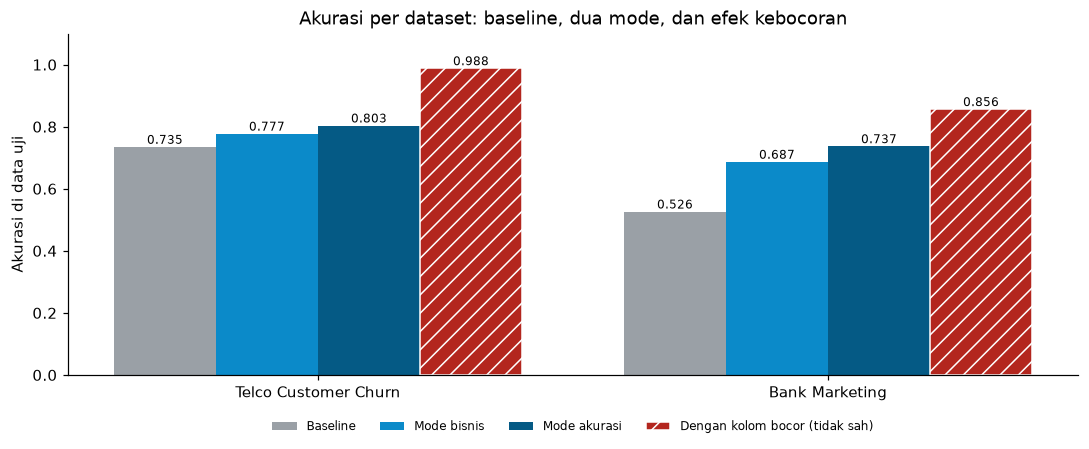

In [40]:
fig, ax = plt.subplots(figsize=(10, 4.2))
names = summary.columns.tolist()
series = [("Baseline", "Akurasi baseline", GREY), ("Mode bisnis", "Akurasi (bisnis)", BLUE),
          ("Mode akurasi", "Akurasi (akurasi)", "#055a85"), ("Dengan kolom bocor (tidak sah)", "Akurasi jika bocor", RED)]
idx = np.arange(len(names))
for i, (label, row, color) in enumerate(series):
    values = summary.loc[row].astype(float).values
    ax.bar(idx + (i - 1.5) * 0.2, values, width=0.2, color=color, label=label,
           hatch="//" if "bocor" in label else None, edgecolor="white" if "bocor" in label else None)
    for x, v in zip(idx + (i - 1.5) * 0.2, values):
        ax.text(x, v + 0.01, f"{v:.3f}", ha="center", fontsize=8)
ax.set_xticks(idx, names)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Akurasi di data uji")
ax.set_title("Akurasi per dataset: baseline, dua mode, dan efek kebocoran")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Perbandingan kedua dataset:**

- **Akurasi mentah tidak bisa dibandingkan langsung antardataset.** Telco terlihat lebih tinggi (0,803 di mode akurasi) daripada Bank (0,737), tetapi Telco juga berangkat dari baseline yang jauh lebih tinggi (0,735 dibanding 0,526). Diukur dari kenaikan di atas baseline, model Bank justru belajar lebih banyak: **+21,1 poin**, dibanding **+6,9 poin** di Telco.
- **Sifat kelas mengubah peran mode bisnis.** Di Telco yang tidak seimbang, bobot kelas dan threshold F1 diperlukan supaya model tidak mengabaikan pelanggan churn. Di Bank yang seimbang, bobot kelas hampir tidak berpengaruh, dan threshold F1 terutama menukar akurasi dengan recall.
- **Model terbaik berbeda per dataset.** Di Telco, Logistic Regression hampir menyamai model boosting; di Bank, model boosting unggul sekitar 3 sampai 4 poin ROC-AUC. Tidak ada satu model yang selalu menang, dan itulah alasan aplikasi menyediakan mode perbandingan.
- **Kebocoran muncul di kedua dataset dalam bentuk berbeda.** Di Telco berupa kolom buatan vendor (skor dan alasan churn); di Bank berupa informasi yang baru ada setelah kejadian (lama telepon). Keduanya tidak tertangkap oleh penjaga otomatis dan hanya bisa dikenali dari pemahaman domain. Tanpa dibuang, akurasi terlihat 0,988 dan 0,856, tetapi angka itu tidak sah.

## Kesimpulan akhir

1. **Pipeline universal bekerja di dua domain yang berbeda** tanpa perubahan kode: jenis kotoran yang berbeda (spasi kosong, kolom konstan, ID, nilai `unknown`) ditangani oleh fungsi yang sama.
2. **Akurasi terbaik yang jujur:** Telco 0,803 (Logistic Regression, mode akurasi) dan Bank 0,737 (HistGradientBoosting, mode akurasi). Dalam mode bisnis, model terbaik adalah CatBoost untuk Telco (F1 0,640) dan LightGBM untuk Bank (F1 0,705).
3. **Akurasi selalu dilaporkan bersama baseline, F1, recall, dan ROC-AUC**, karena akurasi saja menyesatkan, terutama untuk data yang tidak seimbang.
4. **Semua threshold dan pemilihan model berasal dari validasi silang di data latih**, sehingga skor di data uji tidak bias.

**Keterbatasan**

- Hyperparameter tidak di-*tuning*; semua model memakai pengaturan yang sama supaya perbandingan adil.
- Setiap dataset hanya dibagi sekali (80/20); validasi silang di data latih dipakai untuk mengukur kestabilan.
- Telco: `Zip Code` dipakai sebagai angka, dan 11 nilai `Total Charges` diisi median, padahal 0 lebih tepat secara bisnis.
- Bank: `pdays = -1` dipertahankan apa adanya, sehingga model linear bisa salah membacanya. Versi dataset ini adalah sampel seimbang dari Kaggle, bukan data kampanye asli yang tidak seimbang.
- Aplikasi web memakai cara pemilihan threshold yang sama dengan notebook ini (validasi silang 5-fold di data latih), sehingga skor di aplikasi dan di notebook sama untuk data dan model yang sama.

**File hasil**

| | Telco | Bank Marketing |
|---|---|---|
| Data mentah | `data/raw/Telco_customer_churn.csv` | `data/raw/bank.csv` |
| Data bersih | `data/clean/telco_churn_clean.csv` | `data/clean/bank_marketing_clean.csv` |
| Model (mode bisnis) | `models/telco/` | `models/bank/` |
| Model terbaik (mode akurasi) | `models/telco/accuracy_mode/` | `models/bank/accuracy_mode/` |